In [647]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler , RobustScaler , OneHotEncoder 
from sklearn.metrics import (f1_score , mean_squared_error, confusion_matrix , mean_absolute_error , r2_score , root_mean_squared_error , accuracy_score, precision_score, recall_score , classification_report ,silhouette_score)
from sklearn.model_selection import train_test_split , cross_val_score , cross_validate , StratifiedKFold , GridSearchCV , RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 


# models
from sklearn.linear_model import LinearRegression , LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier , NearestNeighbors
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.cluster import KMeans , AgglomerativeClustering , DBSCAN





## Read Data

In [443]:
customers_df = pd.read_csv('../data/raw/customers.csv')
service_trans_df = pd.read_csv('../data/raw/service_transactions.csv')
usage_behave_df = pd.read_csv('../data/raw/usage_behavior.csv')

## Working On Customers Data

In [444]:
customers_df.head()

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,Standard,Cash at store,Android,No,35.2,468.0,37,4,0,0,453.62,No
1,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,No
2,C02273,44.0,Female,Giza,3,1-Year,Basic,Cash at store,Android,No,NaN,398.0,36,3,1,3,239.72,Yes
3,C02864,73.0,Male,Beni Suef,3,Monthly,Premium,Cash at store,iPhone,Yes,25.7,377.0,46,5,0,3,616.94,Yes
4,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,No


In [445]:
customers_df.shape

(3015, 18)

In [446]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        3015 non-null   object 
 1   age                2925 non-null   float64
 2   gender             3015 non-null   object 
 3   governorate        3015 non-null   object 
 4   tenure_months      3015 non-null   int64  
 5   contract_type      3015 non-null   object 
 6   plan               3015 non-null   object 
 7   payment_method     2955 non-null   object 
 8   device_type        3015 non-null   object 
 9   has_home_internet  3015 non-null   object 
 10  data_usage_gb      2925 non-null   float64
 11  voice_minutes      2955 non-null   float64
 12  sms_count          3015 non-null   int64  
 13  num_services       3015 non-null   int64  
 14  support_calls      3015 non-null   int64  
 15  late_payments      3015 non-null   int64  
 16  monthly_bill_egp   3015 

In [447]:

customers_df.isna().sum()

customer_id           0
age                  90
gender                0
governorate           0
tenure_months         0
contract_type         0
plan                  0
payment_method       60
device_type           0
has_home_internet     0
data_usage_gb        90
voice_minutes        60
sms_count             0
num_services          0
support_calls         0
late_payments         0
monthly_bill_egp      0
churn                 0
dtype: int64

In [448]:
customers_df.duplicated().sum()

np.int64(15)

In [449]:
customers_df.describe()

,age,tenure_months,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp
count,2925.000000,3015.000000,2925.000000,2955.000000,3015.000000,3015.000000,3015.000000,3015.000000,3015.000000
mean,36.156923,23.311443,28.861744,293.430457,39.026534,3.403980,1.277944,0.756551,408.742000
std,11.273053,20.427324,38.985413,145.230159,11.297184,1.502481,1.127429,0.890730,195.879821
min,18.000000,1.000000,2.000000,20.000000,5.000000,1.000000,0.000000,0.000000,126.020000
25%,28.000000,7.000000,9.000000,191.000000,31.000000,2.000000,0.000000,0.000000,248.965000
50%,36.000000,17.000000,19.700000,291.000000,41.000000,3.000000,1.000000,1.000000,370.550000
75%,44.000000,34.000000,37.300000,393.000000,47.000000,4.000000,2.000000,1.000000,487.755000
max,74.000000,72.000000,1288.800000,807.000000,68.000000,7.000000,6.000000,5.000000,1598.390000


In [450]:
customers_df.columns

Index(['customer_id', 'age', 'gender', 'governorate', 'tenure_months',
       'contract_type', 'plan', 'payment_method', 'device_type',
       'has_home_internet', 'data_usage_gb', 'voice_minutes', 'sms_count',
       'num_services', 'support_calls', 'late_payments', 'monthly_bill_egp',
       'churn'],
      dtype='object')

## Data Understanding

In [451]:
customer_copy = customers_df.copy()

In [452]:
customer_copy.drop_duplicates(inplace=True)

In [453]:
customer_copy.duplicated().sum()

np.int64(0)

In [454]:
customer_copy.isna().sum()

customer_id           0
age                  90
gender                0
governorate           0
tenure_months         0
contract_type         0
plan                  0
payment_method       60
device_type           0
has_home_internet     0
data_usage_gb        90
voice_minutes        60
sms_count             0
num_services          0
support_calls         0
late_payments         0
monthly_bill_egp      0
churn                 0
dtype: int64

In [455]:
customer_copy[customer_copy['age'].isna()]

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
15,C01390,NaN,Male,Alexandria,4,1-Year,Premium,Cash at store,Android,Yes,43.4,332.0,34,4,0,2,670.31,Yes
21,C01154,NaN,Male,Sharqia,72,Monthly,Basic,Cash at store,iPhone,Yes,12.4,314.0,34,3,1,2,231.22,No
60,C01383,NaN,Female,Dakahlia,33,2-Year,Standard,Bank transfer,Other,No,21.1,463.0,33,4,0,0,430.89,No
80,C02749,NaN,Male,Assiut,22,Monthly,Standard,Credit card,Android,No,57.8,152.0,38,1,1,0,503.89,Yes
104,C01235,NaN,Male,Alexandria,1,Monthly,Standard,Bank transfer,Android,No,14.1,579.0,46,4,2,1,371.26,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2774,C02739,NaN,Female,Minya,36,Monthly,Premium,Mobile wallet,Android,Yes,25.6,48.0,46,5,0,3,553.83,Yes
2804,C02477,NaN,Female,Dakahlia,7,Monthly,Standard,Credit card,Android,Yes,42.1,304.0,18,2,2,0,506.19,No
2807,C02588,NaN,Male,Dakahlia,72,1-Year,Premium,Cash at store,Android,No,86.7,534.0,54,5,0,1,868.63,No
2891,C02331,NaN,Male,Cairo,19,1-Year,Standard,Mobile wallet,iPhone,No,18.9,384.0,24,2,3,0,352.11,No


In [456]:
customer_copy['age'].value_counts() # fill nan using median

age
18.0    236
39.0    112
36.0    108
37.0    102
41.0    101
35.0     99
31.0     95
40.0     94
32.0     92
34.0     92
33.0     87
38.0     83
42.0     82
30.0     81
44.0     81
43.0     79
28.0     76
29.0     74
45.0     74
46.0     73
26.0     71
24.0     65
27.0     63
48.0     62
25.0     57
23.0     56
50.0     52
22.0     47
47.0     46
49.0     46
21.0     43
52.0     39
19.0     37
54.0     37
51.0     37
55.0     32
53.0     31
20.0     30
57.0     22
59.0     17
58.0     16
56.0     15
60.0     11
63.0      9
64.0      8
61.0      8
65.0      6
62.0      6
67.0      4
70.0      4
71.0      3
66.0      3
69.0      2
68.0      2
74.0      1
73.0      1
Name: count, dtype: int64

In [457]:
customer_copy[customer_copy['payment_method'].isna()]


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
91,C00122,38.0,Female,Cairo,23,2-Year,Basic,NaN,Android,No,6.3,478.0,46,6,0,2,229.05,No
105,C02036,45.0,Male,Giza,57,1-Year,Standard,NaN,Android,No,23.0,281.0,45,5,3,1,360.21,No
147,C00768,29.0,Female,Aswan,13,1-Year,Basic,NaN,Android,Yes,4.6,296.0,19,2,1,2,221.03,No
150,C00632,67.0,Female,Aswan,8,2-Year,Premium,NaN,Android,No,39.5,425.0,48,6,2,0,649.55,No
212,C02593,42.0,Male,Assiut,44,Monthly,Standard,NaN,Android,No,23.0,77.0,50,6,0,0,375.80,No
256,C01182,46.0,Male,Minya,13,Monthly,Standard,NaN,iPhone,Yes,14.2,315.0,50,5,1,2,415.05,No
269,C01814,36.0,Female,Cairo,8,2-Year,Standard,NaN,Android,Yes,23.1,301.0,45,3,2,0,403.70,No
399,C02839,50.0,Male,Cairo,1,1-Year,Basic,NaN,Android,No,2.0,118.0,31,3,0,1,178.41,No
498,C00633,31.0,Female,Cairo,55,2-Year,Basic,NaN,Android,Yes,8.1,215.0,50,4,1,0,297.69,No
504,C02080,25.0,Female,Alexandria,36,2-Year,Standard,NaN,Android,No,39.8,161.0,25,2,2,1,383.12,No


In [458]:
customer_copy['payment_method'].value_counts() # we can full nan values here using mod 

payment_method
Mobile wallet    925
Cash at store    858
Credit card      710
Bank transfer    447
Name: count, dtype: int64

In [459]:

customer_copy[customer_copy['data_usage_gb'].isna()]


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
2,C02273,44.0,Female,Giza,3,1-Year,Basic,Cash at store,Android,No,NaN,398.0,36,3,1,3,239.72,Yes
9,C02689,51.0,Male,Cairo,15,Monthly,Standard,Cash at store,iPhone,No,NaN,386.0,50,2,1,1,317.99,Yes
12,C02591,26.0,Male,Giza,46,2-Year,Basic,Bank transfer,iPhone,No,NaN,251.0,22,2,1,1,226.37,No
17,C00796,35.0,Female,Alexandria,3,Monthly,Basic,Credit card,Android,No,NaN,355.0,41,3,5,1,169.85,Yes
22,C02605,50.0,Female,Gharbia,12,Monthly,Basic,Mobile wallet,Android,Yes,NaN,374.0,52,4,2,0,285.93,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2747,C01571,36.0,Male,Assiut,25,2-Year,Standard,Mobile wallet,Android,No,NaN,456.0,44,3,3,0,362.24,No
2790,C02193,24.0,Female,Assiut,39,2-Year,Basic,Cash at store,Android,No,NaN,351.0,24,4,2,2,223.26,No
2845,C01255,27.0,Female,Giza,20,2-Year,Basic,Bank transfer,iPhone,Yes,NaN,58.0,16,5,2,2,272.93,No
2911,C00974,43.0,Male,Aswan,15,Monthly,Basic,Credit card,Android,No,NaN,176.0,56,3,0,0,166.66,No


In [460]:
customer_copy['data_usage_gb'].value_counts().sort_index(ascending=False)

data_usage_gb
1288.8    1
715.2     1
510.0     1
357.6     1
295.1     1
         ..
2.8       1
2.4       1
2.3       1
2.1       1
2.0       1
Name: count, Length: 774, dtype: int64

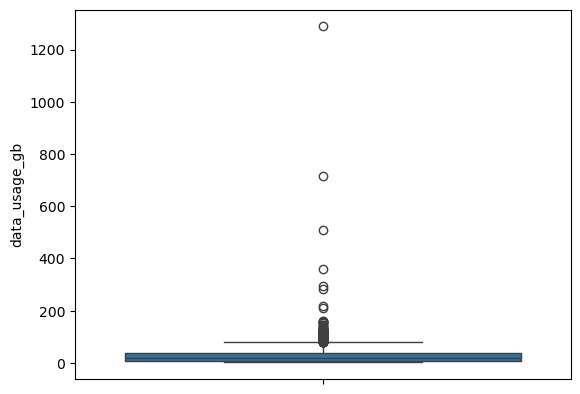

In [461]:
sns.boxplot(customer_copy.data_usage_gb)
plt.show()

In [462]:
x =customer_copy[['monthly_bill_egp' , 'data_usage_gb' ]].dropna().reset_index()


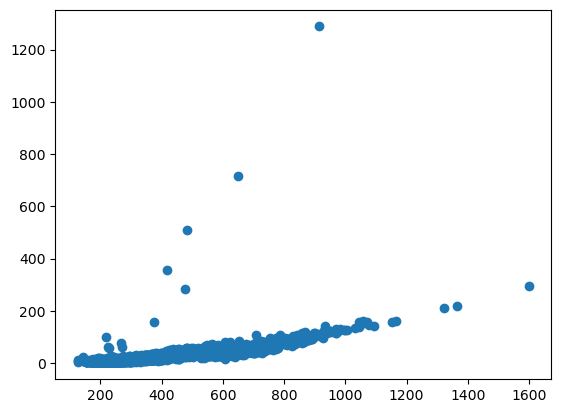

In [463]:
plt.scatter(x['monthly_bill_egp'],x['data_usage_gb'] )

plt.show()

In [464]:
customer_copy['monthly_bill_egp' ].corr(customer_copy['data_usage_gb'], method='spearman')

np.float64(0.915903206241115)

In [465]:
customer_copy[customer_copy['voice_minutes'].isna()]

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
114,C02694,32.0,Male,Giza,8,1-Year,Standard,Cash at store,Android,Yes,31.5,NaN,40,6,1,1,503.02,No
169,C00527,53.0,Female,Giza,2,1-Year,Premium,Mobile wallet,iPhone,Yes,112.2,NaN,40,4,4,2,929.34,Yes
243,C01128,35.0,Male,Gharbia,4,2-Year,Standard,Bank transfer,Android,No,19.5,NaN,41,2,0,0,351.54,No
250,C00581,18.0,Male,Aswan,6,1-Year,Basic,Mobile wallet,iPhone,Yes,17.6,NaN,36,5,0,0,257.50,No
299,C00620,53.0,Male,Alexandria,33,Monthly,Basic,Cash at store,Android,No,NaN,NaN,40,4,0,1,217.52,No
342,C02117,37.0,Female,Alexandria,19,Monthly,Basic,Mobile wallet,iPhone,Yes,10.6,NaN,50,2,1,2,257.15,No
408,C02815,NaN,Male,Cairo,60,2-Year,Premium,Cash at store,iPhone,No,75.2,NaN,44,5,1,0,807.78,No
412,C02454,26.0,Male,Cairo,30,1-Year,Premium,Mobile wallet,Android,Yes,74.1,NaN,22,4,1,0,754.22,No
464,C01553,29.0,Female,Cairo,3,1-Year,Basic,Credit card,Other,No,18.0,NaN,21,2,1,1,190.66,No
468,C02004,39.0,Female,Aswan,16,Monthly,Premium,Credit card,Other,No,72.9,NaN,43,3,2,1,729.48,Yes


<Axes: ylabel='voice_minutes'>

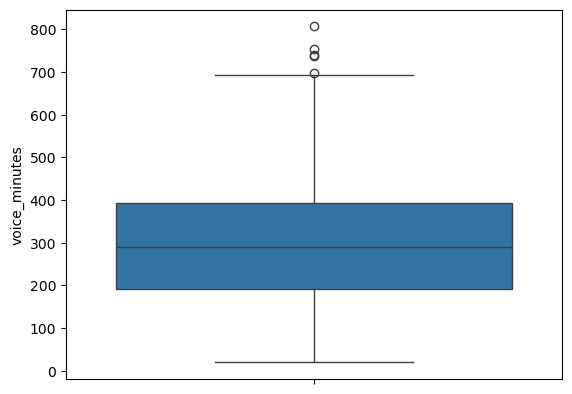

In [466]:
sns.boxplot(customer_copy['voice_minutes'])

## Data Cleaning

### Handling Missing Values

In [467]:
customer_copy['age'] = customer_copy['age'].fillna(customer_copy['age'].median())
customer_copy['age'].isna().sum()

np.int64(0)

In [468]:
customer_copy['payment_method'].mode()

0    Mobile wallet
Name: payment_method, dtype: object

In [469]:
customer_copy['payment_method'] = customer_copy['payment_method'].fillna(customer_copy['payment_method'].mode()[0])
customer_copy['payment_method'].isna().sum()


np.int64(0)

In [470]:
customer_copy[['payment_method']].value_counts()

payment_method
Mobile wallet     985
Cash at store     858
Credit card       710
Bank transfer     447
Name: count, dtype: int64

In [471]:
customer_copy['voice_minutes'] = customer_copy['voice_minutes'].fillna(customer_copy['voice_minutes'].median())
customer_copy['voice_minutes'].isna().sum()

np.int64(0)

In [472]:
customer_copy['data_usage_gb'] = customer_copy['data_usage_gb'].fillna( customer_copy['data_usage_gb'].median())
customer_copy['voice_minutes'].isna().sum()


np.int64(0)

In [473]:
customer_copy.isna().sum()

customer_id          0
age                  0
gender               0
governorate          0
tenure_months        0
contract_type        0
plan                 0
payment_method       0
device_type          0
has_home_internet    0
data_usage_gb        0
voice_minutes        0
sms_count            0
num_services         0
support_calls        0
late_payments        0
monthly_bill_egp     0
churn                0
dtype: int64

## EDA

### **Churn Analysis**

In [474]:
customer_copy['churn'].value_counts()

churn
No     2221
Yes     779
Name: count, dtype: int64

In [475]:
customer_copy['contract_type'].value_counts()

contract_type
Monthly    1526
1-Year      862
2-Year      582
monthly      16
1-year        9
2-year        5
Name: count, dtype: int64

In [476]:
customer_copy['churn'] = customer_copy['churn'].map({
    'Yes' : 1,
    ''
    'No' : 0
})

In [477]:
customer_copy.head()

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,Standard,Cash at store,Android,No,35.2,468.0,37,4,0,0,453.62,0
1,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,0
2,C02273,44.0,Female,Giza,3,1-Year,Basic,Cash at store,Android,No,19.7,398.0,36,3,1,3,239.72,1
3,C02864,73.0,Male,Beni Suef,3,Monthly,Premium,Cash at store,iPhone,Yes,25.7,377.0,46,5,0,3,616.94,1
4,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,0


In [478]:
churn_rate_by_contract = (customer_copy.groupby('contract_type')['churn'].mean()* 100).sort_values(ascending=False).reset_index()  # why mean? -> because churn is a binary column so mean will be a value for 'yes' class (customer left)
churn_rate_by_contract

,contract_type,churn
0,Monthly,41.218873
1,monthly,31.250000
2,1-Year,13.689095
3,1-year,11.111111
4,2-Year,4.467354
5,2-year,0.000000


In [479]:
customer_copy['tenure_months'].value_counts().sort_values(ascending=False)


tenure_months
1     168
72    159
2     123
6     115
3     113
     ... 
70      6
57      5
68      4
67      4
54      3
Name: count, Length: 72, dtype: int64

In [480]:
chrn_reate_by_tenure_group = (customer_copy.groupby('tenure_months')['churn'].mean()*100).sort_index(ascending=False).reset_index()

In [481]:
numeric_cols = customer_copy.select_dtypes(include='number')

In [482]:
numeric_cols.head(
    
)

,age,tenure_months,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,36.0,6,35.2,468.0,37,4,0,0,453.62,0
1,18.0,69,40.7,230.0,23,2,3,0,430.42,0
2,44.0,3,19.7,398.0,36,3,1,3,239.72,1
3,73.0,3,25.7,377.0,46,5,0,3,616.94,1
4,24.0,10,71.6,206.0,18,3,0,0,737.98,0


In [483]:
corr = numeric_cols.corr()
corr

,age,tenure_months,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
age,1.000000,0.029659,-0.108992,0.240285,0.600699,-0.008192,-0.010129,-0.009201,-0.075705,-0.032457
tenure_months,0.029659,1.000000,0.009665,-0.017668,0.033508,0.004959,-0.016012,-0.015802,0.015399,-0.291606
data_usage_gb,-0.108992,0.009665,1.000000,-0.038052,-0.078317,0.126853,0.043055,-0.017894,0.639877,0.248112
voice_minutes,0.240285,-0.017668,-0.038052,1.000000,0.220094,0.003033,0.008253,-0.011862,0.013147,0.031209
sms_count,0.600699,0.033508,-0.078317,0.220094,1.000000,-0.007846,-0.022495,0.004884,-0.052083,-0.020290
num_services,-0.008192,0.004959,0.126853,0.003033,-0.007846,1.000000,-0.006313,-0.029776,0.307148,0.117228
support_calls,-0.010129,-0.016012,0.043055,0.008253,-0.022495,-0.006313,1.000000,-0.000865,0.015535,0.150140
late_payments,-0.009201,-0.015802,-0.017894,-0.011862,0.004884,-0.029776,-0.000865,1.000000,-0.030765,0.191294
monthly_bill_egp,-0.075705,0.015399,0.639877,0.013147,-0.052083,0.307148,0.015535,-0.030765,1.000000,0.365247
churn,-0.032457,-0.291606,0.248112,0.031209,-0.020290,0.117228,0.150140,0.191294,0.365247,1.000000


In [484]:
male_and_femal = customer_copy['gender'].value_counts().reset_index()
male_and_femal  # Same meaning but diffirent syntax

,gender,count
0,Male,1597
1,Female,1383
2,Male,11
3,Female,9


In [485]:
customer_copy['gender'] = customer_copy['gender'].str.strip().replace({

    'Male' : 'Male',
    'Female' : 'Female'

})

In [486]:
male_and_femal = customer_copy['gender'].value_counts().reset_index()
male_and_femal

,gender,count
0,Male,1608
1,Female,1392


In [487]:
payment_methods = customer_copy['payment_method'].value_counts().reset_index()
payment_methods

,payment_method,count
0,Mobile wallet,985
1,Cash at store,858
2,Credit card,710
3,Bank transfer,447


In [488]:
chrn_pct = (customer_copy['churn'].value_counts(normalize=True)*100).reset_index()
chrn_pct

,churn,proportion
0,0,74.033333
1,1,25.966667


- Accuracy can be misleading because the dataset is imbalanced: 74% of customers do not churn, while only 26% do
- A model that predicts every customer as non-churn would achieve about 74% accuracy
- However, it would fail to identify any churn customers, making it useless for the business

## **Charts**

In [489]:
def clean_charts_matplot(ax , title : str , x_label : str , y_lable:str):

    ax.grid(True , alpha=0.3)
    ax.set_title(title , fontsize = 14 , fontweight = "bold" , ha="center")
    ax.set_xlabel(x_label , fontsize = 12  , ha="center")
    ax.set_ylabel(y_lable , fontsize = 12  , ha="center")
    plt.tight_layout()
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    return ax

### **age analysis**

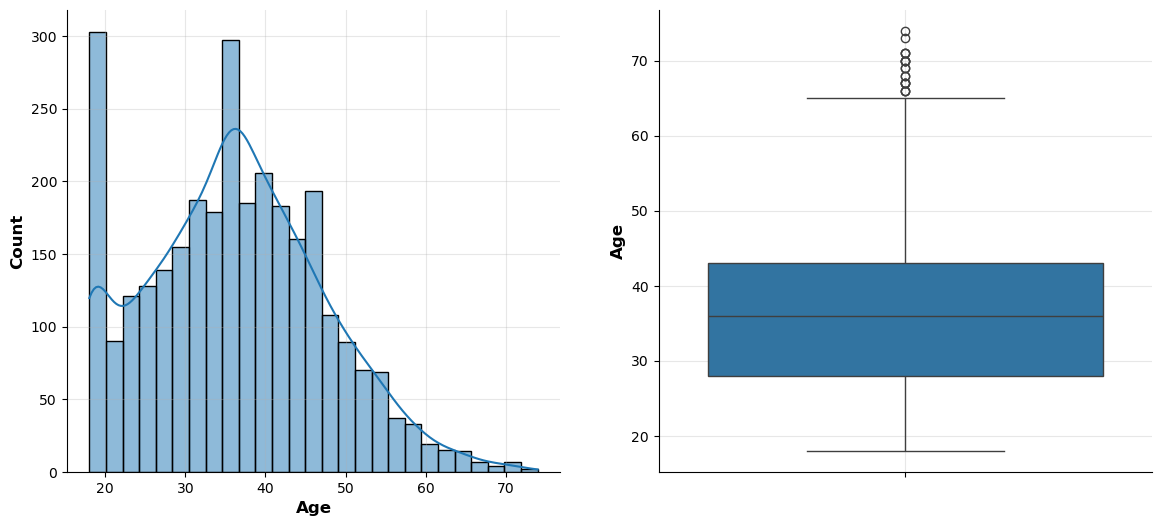

In [490]:
fig , ax = plt.subplots(1,2,figsize=(14,6) )


sns.histplot(customer_copy.age , kde=True , ax=ax[0])  
sns.boxplot(customer_copy["age"] , ax = ax[1])
sns.despine( top= True , right=True)

ax[0].set_xlabel('Age' , fontsize=12 , fontweight = "bold" , ha="center")
ax[0].set_ylabel('Count' , fontsize=12 , fontweight = "bold" , ha="center")
ax[1].set_ylabel('Age' , fontsize=12 , fontweight = "bold" , ha="center")



ax[0].grid(True , alpha= 0.3)
ax[1].grid(True , alpha= 0.3)

plt.show()

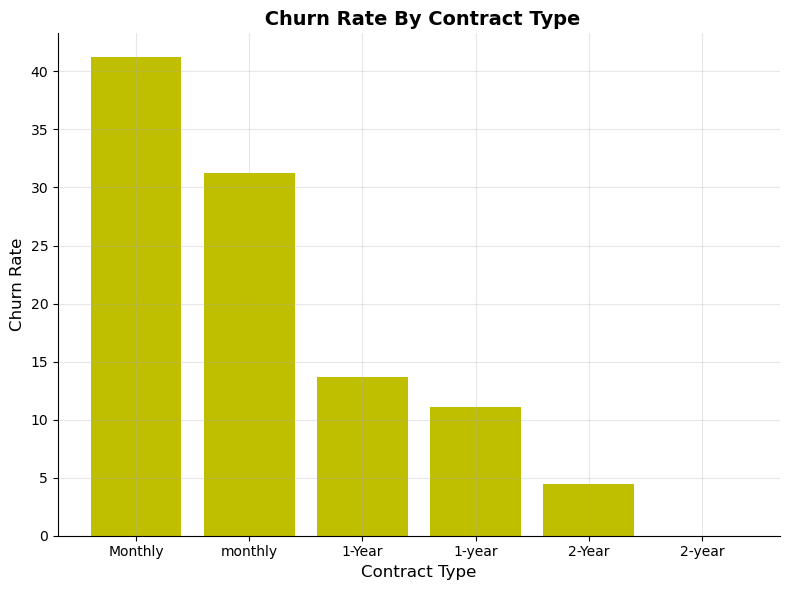

In [491]:
fig , ax = plt.subplots(figsize=(8,6))


ax.bar(churn_rate_by_contract['contract_type'] , churn_rate_by_contract['churn'] , color='y')
ax = clean_charts_matplot(ax , " Churn Rate By Contract Type" , 'Contract Type' , 'Churn Rate' )


plt.show()

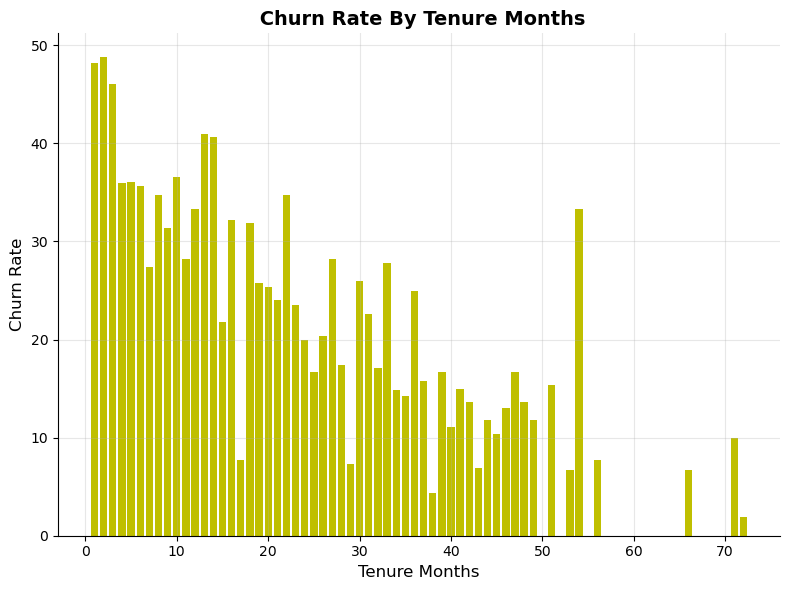

In [492]:
fig , ax = plt.subplots(figsize=(8,6))


ax.bar(chrn_reate_by_tenure_group['tenure_months'] , chrn_reate_by_tenure_group['churn'] , color='y')
ax = clean_charts_matplot(ax , " Churn Rate By Tenure Months" , 'Tenure Months' , 'Churn Rate' )

plt.show()

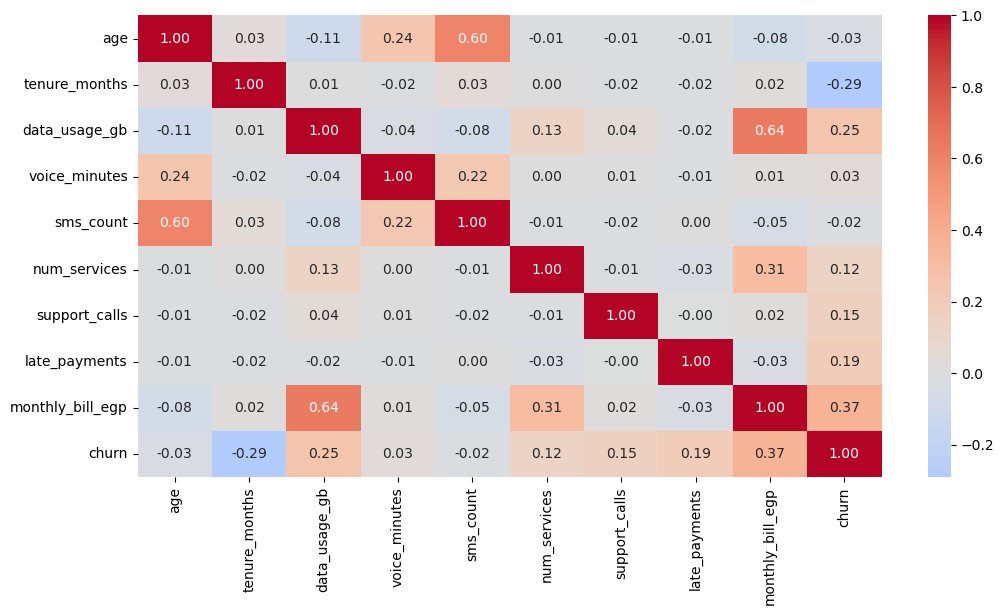

In [493]:
fig , ax = plt.subplots(figsize=(12,6))
sns.heatmap(corr , annot=True , fmt='0.2f' , cmap='coolwarm' , center=0)

plt.show()

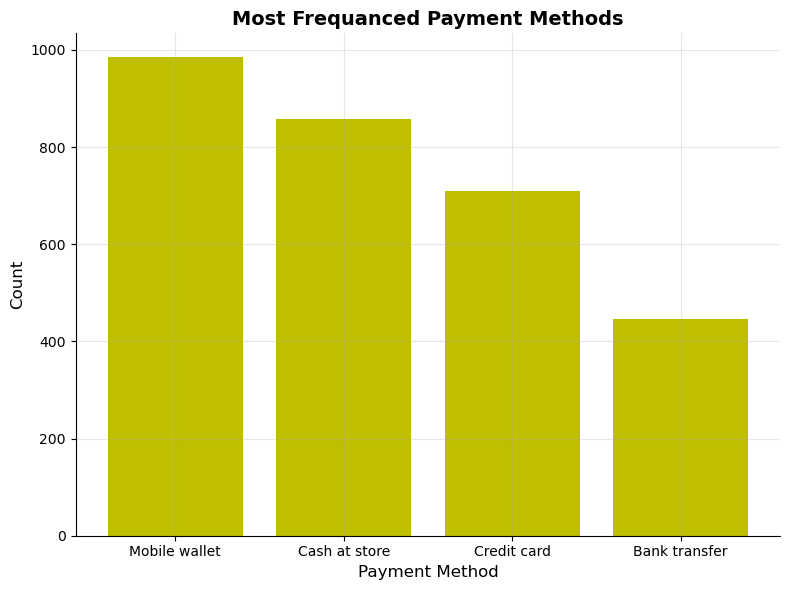

In [494]:
fig , ax = plt.subplots(figsize=(8,6))


ax.bar(payment_methods['payment_method'] , payment_methods['count'] , color='y')
ax = clean_charts_matplot(ax , "Most Frequanced Payment Methods" , 'Payment Method' , 'Count' )


plt.show()

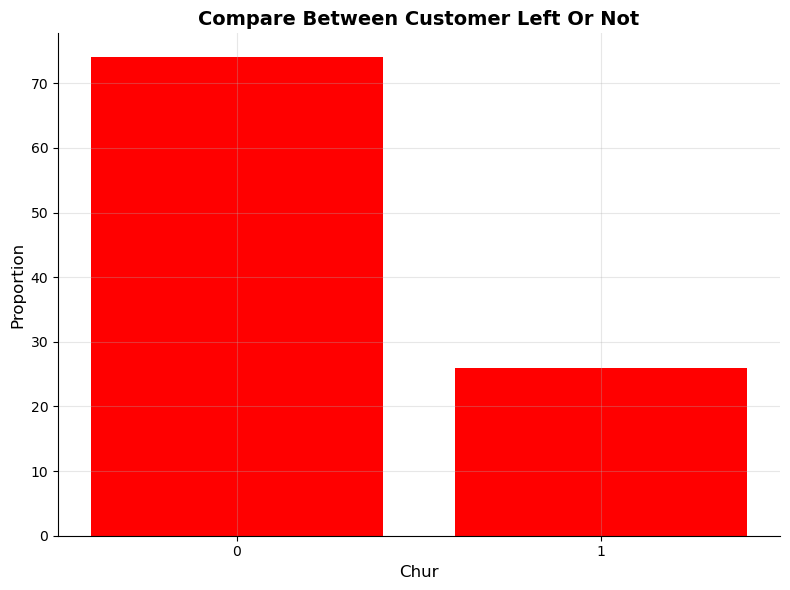

In [495]:
fig , ax = plt.subplots(figsize=(8,6))


ax.bar(chrn_pct['churn'] , chrn_pct['proportion'] , color='r')
ax = clean_charts_matplot(ax , "Compare Between Customer Left Or Not" , 'Chur' , 'Proportion' )
plt.xticks([0,1] , ['0','1'])

plt.show()

## Service Transaction Data Analysis 

In [496]:
service_trans_df.head()

,transaction_id,service
0,T02071,Extra_Minutes
1,T03753,Roaming_Pack
2,T02047,Cloud_Storage
3,T00394,Home_Internet
4,T02490,Extra_Minutes


In [497]:
service_trans_df.shape

(12993, 2)

In [498]:
service_trans_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12993 entries, 0 to 12992
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  12993 non-null  object
 1   service         12993 non-null  object
dtypes: object(2)
memory usage: 203.1+ KB


In [499]:
service_trans_df.describe()

,transaction_id,service
count,12993,12993
unique,4500,13
top,T03109,Mobile_Data_Pack
freq,11,2338


In [500]:
service_trans_df.duplicated().sum()

np.int64(0)

In [501]:
service_trans_df.isna().sum()

transaction_id    0
service           0
dtype: int64

 **Data Is Cleaning**

---

## Usage Behave Data

### **Data Understanding**

In [502]:
usage_behave_df.head()

,customer_id,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
0,C00001,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1
1,C00002,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7
2,C00003,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1
3,C00004,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2
4,C00005,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9


In [503]:
usage_behave_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              2000 non-null   object 
 1   avg_daily_data_mb        2000 non-null   float64
 2   night_usage_pct          2000 non-null   float64
 3   streaming_hours_week     2000 non-null   float64
 4   social_media_hours_week  1975 non-null   float64
 5   gaming_hours_week        2000 non-null   float64
 6   calls_per_day            2000 non-null   float64
 7   avg_call_minutes         2000 non-null   float64
 8   intl_calls_month         2000 non-null   int64  
 9   roaming_days_year        2000 non-null   int64  
 10  topups_per_month         2000 non-null   int64  
 11  app_count                2000 non-null   int64  
 12  video_call_hours_week    2000 non-null   float64
dtypes: float64(8), int64(4), object(1)
memory usage: 203.3+ KB


In [504]:
usage_behave_df.shape

(2000, 13)

In [505]:
usage_behave_df.describe()

,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
count,2000.000000,2000.000000,2000.000000,1975.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000
mean,1399.681950,22.523350,5.118850,7.807696,2.768950,6.533700,2.54280,2.643500,6.460000,3.557000,23.494500,2.53030
std,1358.401177,14.688606,5.695329,5.294717,3.396021,5.614551,1.18096,3.528687,8.435697,1.423293,12.627062,1.69866
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.10000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,480.875000,11.700000,0.600000,2.700000,0.000000,2.900000,1.70000,0.000000,0.000000,2.000000,12.000000,1.30000
50%,993.850000,19.250000,2.650000,8.200000,1.200000,4.800000,2.30000,1.000000,3.000000,4.000000,26.000000,2.40000
75%,2372.225000,32.500000,10.925000,12.400000,5.500000,7.500000,3.00000,3.000000,8.000000,4.000000,34.000000,3.60000
max,8972.300000,94.000000,20.300000,19.800000,14.400000,49.900000,6.00000,13.000000,32.000000,8.000000,52.000000,6.90000


In [506]:
usage_behave_df.isna().sum()

customer_id                 0
avg_daily_data_mb           0
night_usage_pct             0
streaming_hours_week        0
social_media_hours_week    25
gaming_hours_week           0
calls_per_day               0
avg_call_minutes            0
intl_calls_month            0
roaming_days_year           0
topups_per_month            0
app_count                   0
video_call_hours_week       0
dtype: int64

In [507]:
usage_behave_df.duplicated().sum()

np.int64(0)

### **Handling Missing Values**

In [508]:
usage_behave_df['social_media_hours_week'] = usage_behave_df['social_media_hours_week'].fillna(usage_behave_df['social_media_hours_week'].mean())

In [509]:
usage_behave_df.isna().sum()

customer_id                0
avg_daily_data_mb          0
night_usage_pct            0
streaming_hours_week       0
social_media_hours_week    0
gaming_hours_week          0
calls_per_day              0
avg_call_minutes           0
intl_calls_month           0
roaming_days_year          0
topups_per_month           0
app_count                  0
video_call_hours_week      0
dtype: int64

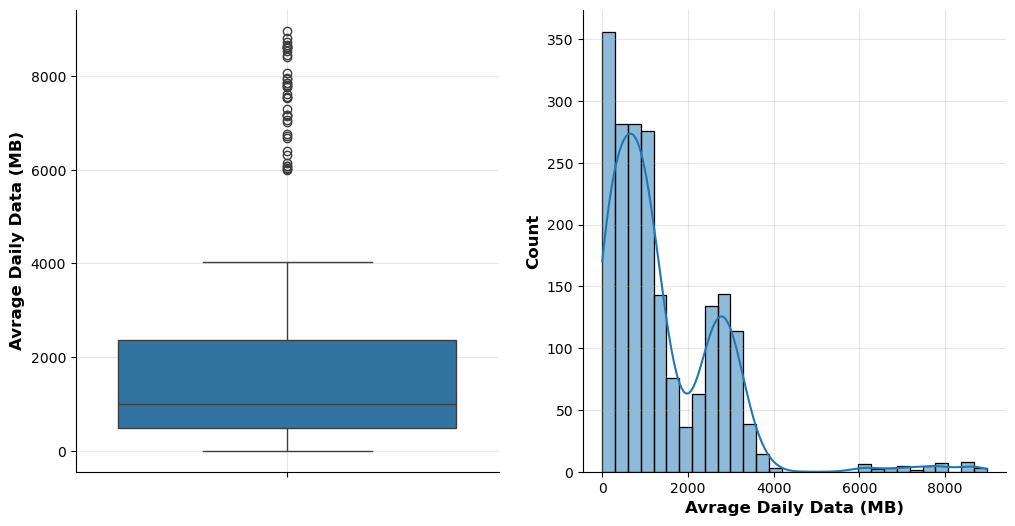

In [510]:
fig , ax = plt.subplots( 1 , 2 ,  figsize=(12,6))
sns.boxplot(usage_behave_df['avg_daily_data_mb'] , ax=ax[0])

sns.histplot(
    data=usage_behave_df,
    x='avg_daily_data_mb',
    kde=True,
    ax=ax[1]
)

sns.despine( top= True , right=True)

ax[1].set_xlabel('Avrage Daily Data (MB)' , fontsize=12 , fontweight = "bold" , ha="center")
ax[1].set_ylabel('Count' , fontsize=12 , fontweight = "bold" , ha="center")
ax[0].set_ylabel('Avrage Daily Data (MB)' , fontsize=12 , fontweight = "bold" , ha="center")



ax[0].grid(True , alpha= 0.3)
ax[1].grid(True , alpha= 0.3)


plt.show()

-The feature is positively skewed (Right-Skewed)

-The distribution shows two noticeable peaks

-Several extreme values exist, which may represent heavy data users rather than errors

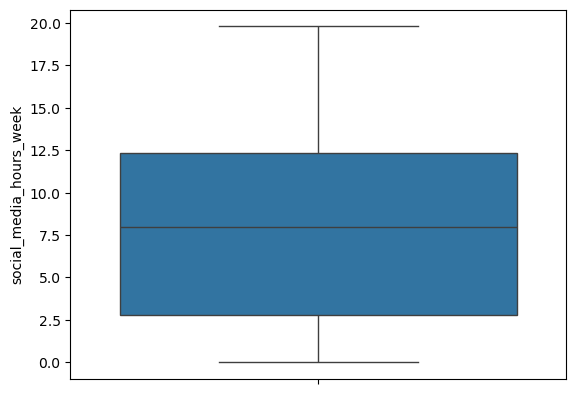

In [511]:
sns.boxplot(usage_behave_df['social_media_hours_week'])
plt.show()

In [512]:
usage_corr = usage_behave_df.drop(columns='customer_id').corr()

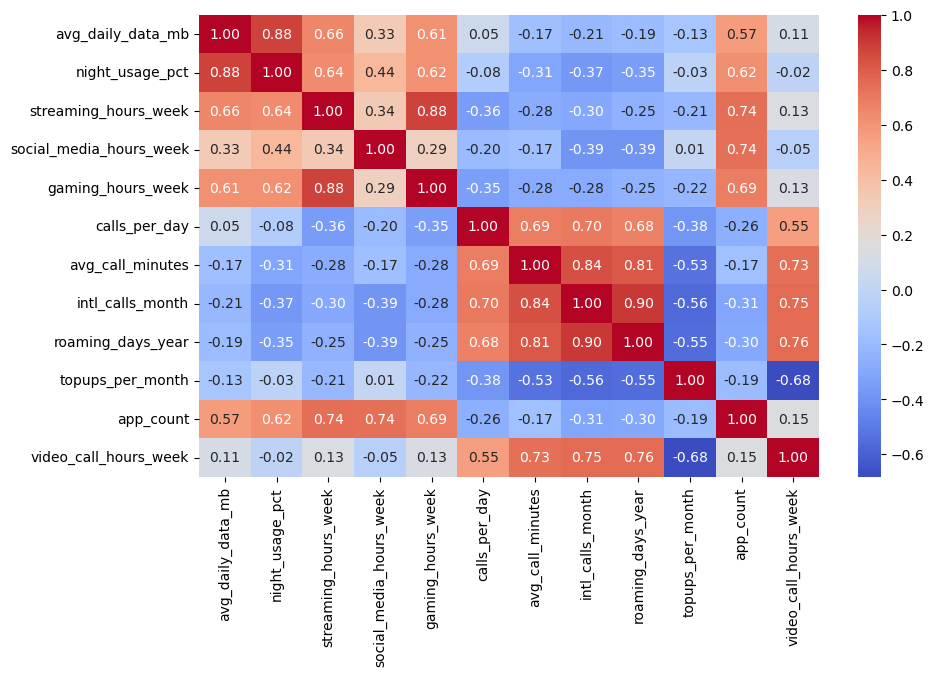

In [513]:
plt.figure(figsize = (10,6))

sns.heatmap(usage_corr , annot=True , fmt='0.2f', cmap='coolwarm')

plt.show()

## ML Part 

In [514]:
customer_copy.columns.tolist()

['customer_id',
 'age',
 'gender',
 'governorate',
 'tenure_months',
 'contract_type',
 'plan',
 'payment_method',
 'device_type',
 'has_home_internet',
 'data_usage_gb',
 'voice_minutes',
 'sms_count',
 'num_services',
 'support_calls',
 'late_payments',
 'monthly_bill_egp',
 'churn']

### Regrission

#### simle linear regression

In [515]:
x = customer_copy[['data_usage_gb']]

y = customer_copy['monthly_bill_egp']

In [516]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2 , random_state=42  )

In [517]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [518]:
model = LinearRegression()
model.fit(x_train_scaled , y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [519]:
print("Slope is : ", model.coef_)
print("Intercipt is : ", model.intercept_)


Slope is :  [123.05044653]
Intercipt is :  410.09499166666666


In [520]:
y_predict = model.predict(x_test_scaled)

In [521]:
RMSE = root_mean_squared_error(y_test , y_predict)
MAE = mean_absolute_error(y_test , y_predict)
R2 = r2_score(y_test , y_predict)

In [522]:
print("RMSE : ", RMSE)
print("MAE : ", MAE)
print("R2 : ", R2)

RMSE :  131.55843836225299
MAE :  104.49863178920882
R2 :  0.5001910993739165


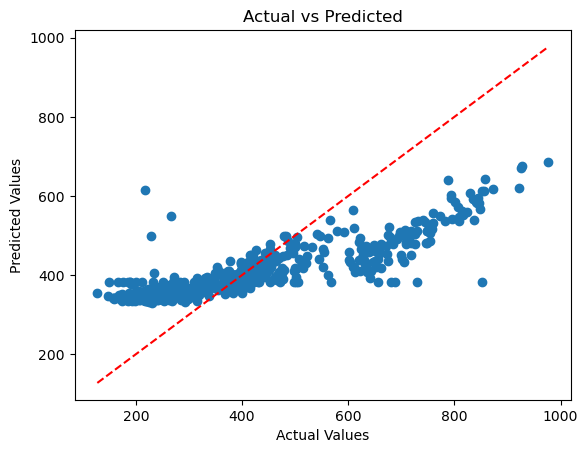

In [523]:
plt.scatter(y_test, y_predict)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')

plt.show()

In [524]:
customer_copy.head()

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,Standard,Cash at store,Android,No,35.2,468.0,37,4,0,0,453.62,0
1,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,0
2,C02273,44.0,Female,Giza,3,1-Year,Basic,Cash at store,Android,No,19.7,398.0,36,3,1,3,239.72,1
3,C02864,73.0,Male,Beni Suef,3,Monthly,Premium,Cash at store,iPhone,Yes,25.7,377.0,46,5,0,3,616.94,1
4,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,0


In [525]:
customer_copy['plan'].value_counts()

plan
Standard    1185
Basic       1183
Premium      632
Name: count, dtype: int64

### **Encoding**

In [526]:
from sklearn.preprocessing import OrdinalEncoder


In [527]:
ordinal_endoder = OrdinalEncoder(
    categories=[[
        'Basic',
        'Standard',
        'Premium'
    ]]
)
customer_copy['plan'] = ordinal_endoder.fit_transform(customer_copy[['plan']])


In [528]:
customer_copy.head()

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,1.0,Cash at store,Android,No,35.2,468.0,37,4,0,0,453.62,0
1,C00641,18.0,Female,Minya,69,Monthly,1.0,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,0
2,C02273,44.0,Female,Giza,3,1-Year,0.0,Cash at store,Android,No,19.7,398.0,36,3,1,3,239.72,1
3,C02864,73.0,Male,Beni Suef,3,Monthly,2.0,Cash at store,iPhone,Yes,25.7,377.0,46,5,0,3,616.94,1
4,C01307,24.0,Male,Aswan,10,Monthly,2.0,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,0


In [529]:
customer_copy['has_home_internet'] = customer_copy['has_home_internet'].map({
    'Yes' : 1,
    'No' : 0
})

In [530]:
x = customer_copy.drop(columns=['customer_id' , 'gender','governorate','contract_type','payment_method','device_type' , 'monthly_bill_egp'])
y = customer_copy['monthly_bill_egp']

In [531]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2 , random_state=42 )


In [532]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [533]:
model = LinearRegression()
model.fit(x_train_scaled , y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [534]:
print("Slope is : ", model.coef_)
print("Intercipt is : ", model.intercept_)

Slope is :  [ -9.35073918   2.63620007 152.90017192  15.06452768  39.13258911
  14.28450861  -4.23137796  20.50100876  -2.42942132  -0.67149972
  11.31913333]
Intercipt is :  410.09499166666666


In [535]:
x_train.columns

Index(['age', 'tenure_months', 'plan', 'has_home_internet', 'data_usage_gb',
       'voice_minutes', 'sms_count', 'num_services', 'support_calls',
       'late_payments', 'churn'],
      dtype='object')

In [536]:
coef_df = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': model.coef_
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

coef_df.sort_values(
    by='Abs_Coefficient',
    ascending=False
).head(3)

,Feature,Coefficient,Abs_Coefficient
2,plan,152.900172,152.900172
4,data_usage_gb,39.132589,39.132589
7,num_services,20.501009,20.501009


- **plan (+152.9):** This makes sense because upgrading to a higher plan usually results in a higher bill

- **data_usage_gb (+39.13):** This is reasonable because increased internet usage can lead to higher charges

- **num_services (+20.50):** This is logical because customers who subscribe to more services are likely to pay more

In [537]:
y_predict = model.predict(x_test_scaled)


In [538]:
RMSE = root_mean_squared_error(y_test , y_predict)
MAE = mean_absolute_error(y_test , y_predict)
R2 = r2_score(y_test , y_predict)

print("RMSE : ", RMSE)
print("MAE : ", MAE)
print("R2 : ", R2)

RMSE :  52.1149274184443
MAE :  40.441864714301374
R2 :  0.9215684421963233


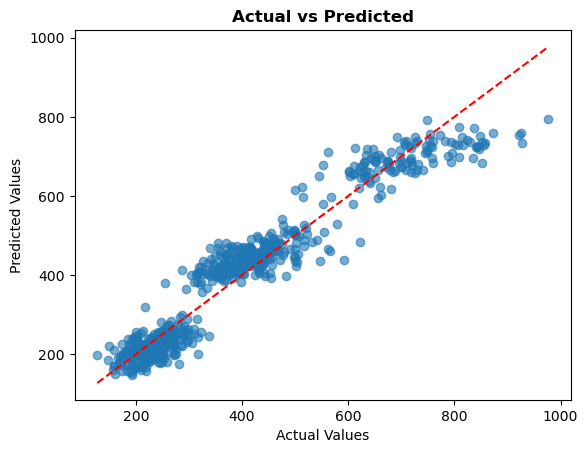

In [539]:
plt.scatter(y_test, y_predict  , alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted' , fontweight="bold")

plt.show()

In [540]:
residuals = y_test - y_predict

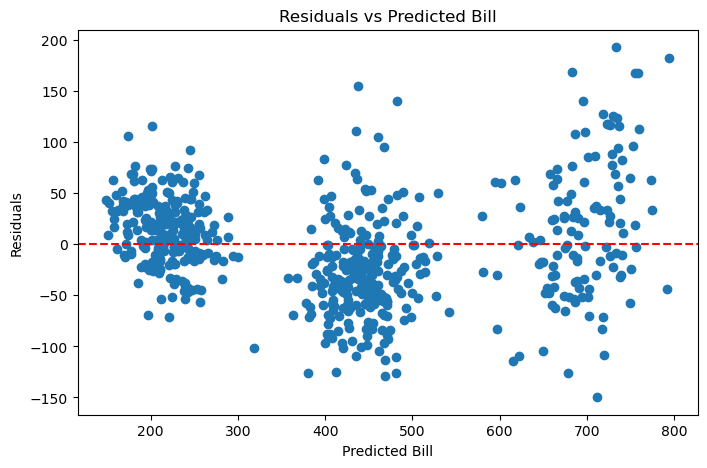

In [541]:
plt.figure(figsize=(8, 5))

plt.scatter(y_predict, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Bill')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Bill')

plt.show()

## Classification  

In [542]:
customer_copy.head()

,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,1.0,Cash at store,Android,0,35.2,468.0,37,4,0,0,453.62,0
1,C00641,18.0,Female,Minya,69,Monthly,1.0,Bank transfer,iPhone,1,40.7,230.0,23,2,3,0,430.42,0
2,C02273,44.0,Female,Giza,3,1-Year,0.0,Cash at store,Android,0,19.7,398.0,36,3,1,3,239.72,1
3,C02864,73.0,Male,Beni Suef,3,Monthly,2.0,Cash at store,iPhone,1,25.7,377.0,46,5,0,3,616.94,1
4,C01307,24.0,Male,Aswan,10,Monthly,2.0,Cash at store,Android,1,71.6,206.0,18,3,0,0,737.98,0


### Define X , Y & Splitting Data

In [543]:
x = customer_copy.drop(columns=['customer_id' , 'churn'])
y = customer_copy['churn']

In [544]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2 , stratify=y , random_state=42)

In [545]:
numeric_features = x.select_dtypes(include='number').columns
numeric_features


Index(['age', 'tenure_months', 'plan', 'has_home_internet', 'data_usage_gb',
       'voice_minutes', 'sms_count', 'num_services', 'support_calls',
       'late_payments', 'monthly_bill_egp'],
      dtype='object')

In [546]:
categorical_features = x.select_dtypes(include=['object' , 'category']).columns
categorical_features

Index(['gender', 'governorate', 'contract_type', 'payment_method',
       'device_type'],
      dtype='object')

### Pipline & Column Transform

In [547]:
numeric_scaled = Pipeline([
    ('scaler' , StandardScaler())
])

cat_transform = Pipeline([
    ('encoder' , OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [548]:
scaled_preprocessor = ColumnTransformer([

    ('num' , numeric_scaled , numeric_features),

    ('cat' , cat_transform , categorical_features)
])


# unscaled pipline because some models don't need scalled data
unscaled_preprocessor = ColumnTransformer([
    ('num' , 'passthrough' , numeric_features),  # passthrogh meaning keep Numerical Features without changing
    ('cat' , cat_transform , categorical_features)
])

### Models & Training

In [549]:
models = {
    'LogisticRegression' : Pipeline([('Preprocessor' , scaled_preprocessor) , ('model' , LogisticRegression())]),
    'SVM' : Pipeline([('Preprocessor' , scaled_preprocessor ) , ('model' , SVC())]),
    'Decision Tree' : Pipeline([('Preprocessor' , unscaled_preprocessor ) , ('model' , DecisionTreeClassifier())]),
    'KNN' : Pipeline([('Preprocessor' , scaled_preprocessor ) , ('model' , KNeighborsClassifier())]),
    'Neive Bayes' : Pipeline([('Preprocessor' , unscaled_preprocessor ) , ('model' , GaussianNB())]),
    'Random Forest' : Pipeline([('Preprocessor' , unscaled_preprocessor ) , ('model' , RandomForestClassifier())]),
    'XGBoost' : Pipeline([('Preprocessor' , unscaled_preprocessor ) , ('model' , XGBClassifier(eval_metric='logloss',random_state=42))])
}

In [550]:
trained_model = {}
for name , model in models.items():
        model.fit(x_train , y_train)
        trained_model[name] = model
        print(f'Model {name} is trained')

Model LogisticRegression is trained
Model SVM is trained
Model Decision Tree is trained
Model KNN is trained
Model Neive Bayes is trained
Model Random Forest is trained
Model XGBoost is trained


### **Models And Thier Result**

In [551]:
result = []

for name , model in trained_model.items():
    y_pred = model.predict(x_test)
    result.append({
        'Model' : name,
       'Accuracy' : accuracy_score(y_test , y_pred),
       'Precision' : precision_score(y_test , y_pred),  
       'Recall' : recall_score(y_test , y_pred),
       'F1 score' : f1_score(y_test , y_pred)
    })

    result_df = pd.DataFrame(result)

In [552]:
result_df

,Model,Accuracy,Precision,Recall,F1 score
0,LogisticRegression,0.851667,0.751880,0.641026,0.692042
1,SVM,0.860000,0.805085,0.608974,0.693431
2,Decision Tree,0.781667,0.577640,0.596154,0.586751
3,KNN,0.803333,0.666667,0.487179,0.562963
4,Neive Bayes,0.758333,0.519435,0.942308,0.669704
5,Random Forest,0.845000,0.773913,0.570513,0.656827
6,XGBoost,0.833333,0.722222,0.583333,0.645390


In [553]:
result_df = result_df.sort_values(
    by='F1 score',
    ascending=False
).reset_index(drop=True)

result_df.round(4)

,Model,Accuracy,Precision,Recall,F1 score
0,SVM,0.8600,0.8051,0.6090,0.6934
1,LogisticRegression,0.8517,0.7519,0.6410,0.6920
2,Neive Bayes,0.7583,0.5194,0.9423,0.6697
3,Random Forest,0.8450,0.7739,0.5705,0.6568
4,XGBoost,0.8333,0.7222,0.5833,0.6454
5,Decision Tree,0.7817,0.5776,0.5962,0.5868
6,KNN,0.8033,0.6667,0.4872,0.5630


In [554]:
best_two_models = result_df['Model'].head(2)

best_two_models




0                   SVM
1    LogisticRegression
Name: Model, dtype: object

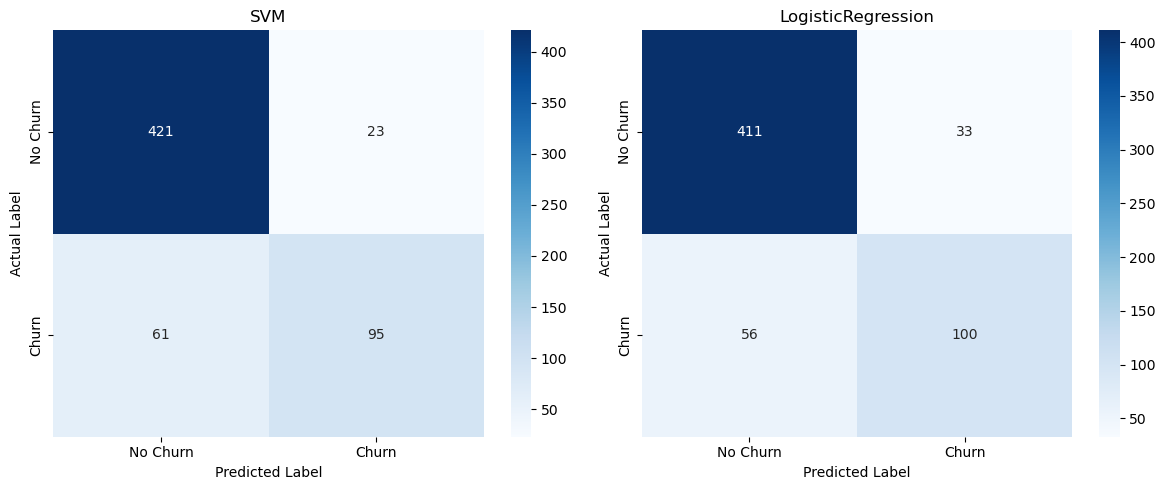

In [555]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, best_two_models):

    model = trained_model[name]

    y_pred = model.predict(x_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

- False Negative (FN): A customer actually leaves the company (Churn = 1), but the model predicts that they will stay (No Churn = 0). The company fails to identify this customer and may lose them without attempting to retain them.

- False Positive (FP): A customer actually stays with the company (No Churn = 0), but the model predicts that they will leave (Churn = 1). The company may unnecessarily spend money on a retention offer for a customer who was not planning to leave.

Which one costs the company more?

- A False Negative generally costs the company more because it represents a lost customer, which costs 1,500 EGP, while a False Positive results in an unnecessary retention offer costing only 200 EGP.

In [556]:
top_3_models = result_df['Model'].head(3)

business_results = []

for name in top_3_models:

    model = trained_model[name]
    y_pred = model.predict(x_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    lost_customers_cost = fn * 1500
    retention_offers_cost = (tp + fp) * 200

    total_cost = lost_customers_cost + retention_offers_cost

    business_results.append({
        'Model': name,
        'Lost Customers Cost': lost_customers_cost,
        'Retention Offers Cost': retention_offers_cost,
        'Total Cost': total_cost
    })

business_df = pd.DataFrame(business_results)

business_df.sort_values(
    by='Total Cost',
    ascending=True
).reset_index(drop=True)

,Model,Lost Customers Cost,Retention Offers Cost,Total Cost
0,Neive Bayes,13500,56600,70100
1,LogisticRegression,84000,26600,110600
2,SVM,91500,23600,115100


In [557]:
print("Best F1 Model:", result_df.iloc[0]['Model'])

print(
    "Best Money Model:",
    business_df.sort_values('Total Cost').iloc[0]['Model']
)

Best F1 Model: SVM
Best Money Model: Neive Bayes


the best-F1 model is not necessarily the best-money model. Naive Bayes achieved the lowest business cost (70,100 EGP), making it the most cost-effective model among the three evaluated models

## Fair comparison and tuning 

In [558]:
print('X_train shape:', x_train.shape)
print('y_train shape:', np.shape(y_train))

print('X_train type:', type(x_train))
print('y_train type:', type(y_train))

# print('CV:', cv)

X_train shape: (2400, 16)
y_train shape: (2400,)
X_train type: <class 'pandas.core.frame.DataFrame'>
y_train type: <class 'pandas.core.series.Series'>


### **Cross Validation**

In [559]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy' : 'accuracy',
    'precision' : 'precision',
    'recall' : 'recall',
    'f1' : 'f1'
}

cv_result={}
for name , model in models.items():
    cross_val = cross_validate(model , x_train , y_train , cv= cv , scoring=scoring )
    cv_result[name] = {
        'Accuracy' : cross_val['test_accuracy'].mean(),
        'Precision' : cross_val['test_precision'].mean(),
        'Recall' : cross_val['test_recall'].mean(),
        'F1 Mean' : cross_val['test_f1'].mean(),
        'F1 Std' : cross_val['test_f1'].std()
    }

cv_df = pd.DataFrame(cv_result).T
cv_df = cv_df.sort_values(
    by='F1 Mean',
    ascending=False
)

In [560]:

cv_df


,Accuracy,Precision,Recall,F1 Mean,F1 Std
LogisticRegression,0.861250,0.763638,0.675729,0.716402,0.020193
SVM,0.852083,0.779459,0.601961,0.678343,0.016990
XGBoost,0.837500,0.713346,0.632426,0.668588,0.035835
Random Forest,0.850000,0.789108,0.576258,0.665780,0.027669
Neive Bayes,0.754583,0.517914,0.892426,0.654440,0.018218
KNN,0.815833,0.686697,0.545755,0.606288,0.017228
Decision Tree,0.789583,0.590607,0.621252,0.604670,0.017650


- Decision Tree: Most stable model, because it has the lowest standard deviation.
- Logistic Regression: Best overall F1 Mean (0.7164), with relatively good stability.
- XGBoost: Least stable model because it has the highest standard deviation.

### **Grid Search Cross Validation**

In [561]:
lr_pipeline = models['LogisticRegression']
param_grid = {

    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(estimator= lr_pipeline , param_grid= param_grid , scoring ='f1' , cv=cv ,verbose=1)

In [562]:
import time

In [563]:
start_time = time.time()

grid_search.fit(x_train , y_train)

end_time = time.time()
grid_time = end_time - start_time
print('Best Parameters:', grid_search.best_params_)
print('Best F1 Score:', grid_search.best_score_)
print(f'Grid Time {grid_time:.2f}')


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best F1 Score: 0.736580073911794
Grid Time 26.59


In [564]:
best_lr_model = grid_search.best_estimator_

y_pred = best_lr_model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.82      0.87       444
           1       0.62      0.83      0.71       156

    accuracy                           0.82       600
   macro avg       0.78      0.83      0.79       600
weighted avg       0.85      0.82      0.83       600



In [565]:
param_dist = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10, 15],
    'model__min_samples_leaf': [1, 2, 4, 6],
    'model__max_features': ['sqrt', 'log2', None],
    'model__class_weight': [None, 'balanced', 'balanced_subsample']
}

In [566]:
random_search = RandomizedSearchCV(
    estimator=models['Random Forest'],
    param_distributions=param_dist,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()

random_search.fit(x_train, y_train)

end_time = time.time()
random_time = end_time - start_time
print('Best Parameters:', random_search.best_params_)
print('Best F1 Score:', random_search.best_score_)
print(f'Execution Time: {random_time:.2f} seconds')

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'model__n_estimators': 200, 'model__min_samples_split': 15, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 10, 'model__class_weight': 'balanced'}
Best F1 Score: 0.7128499573976795
Execution Time: 206.67 seconds


In [567]:
best_rf_model = random_search.best_estimator_

y_pred = best_rf_model.predict(x_test)

print(classification_report(y_test, y_pred))

print('Test F1 Score:', f1_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.90       444
           1       0.69      0.75      0.72       156

    accuracy                           0.85       600
   macro avg       0.80      0.82      0.81       600
weighted avg       0.85      0.85      0.85       600

Test F1 Score: 0.72


In [568]:
comparison = pd.DataFrame([
    {
        'Search Method': 'GridSearchCV',
        'Best F1 Score': grid_search.best_score_,
        'Time (Seconds)': grid_time,
        'Combinations Tried': len(grid_search.cv_results_['params'])
    },
    {
        'Search Method': 'RandomizedSearchCV',
        'Best F1 Score': random_search.best_score_,
        'Time (Seconds)': random_time,
        'Combinations Tried': len(random_search.cv_results_['params'])
    }
])

comparison




,Search Method,Best F1 Score,Time (Seconds),Combinations Tried
0,GridSearchCV,0.73658,26.585478,10
1,RandomizedSearchCV,0.71285,206.674473,30


GridSearchCV evaluates all possible combinations within the specified parameter grid, making it suitable for smaller search spaces where a thorough search is desired.

On the other hand, RandomizedSearchCV evaluates a fixed number of randomly selected combinations, making it more efficient for larger search spaces.

In real-world projects, GridSearchCV is preferred when the search space is relatively small, while RandomizedSearchCV is a better choice when dealing with many hyperparameters and limited computational resources.

The final choice should consider execution time, cross-validation F1 score, and computational cost.

### Choose The Best Model

In [569]:
final_model = grid_search.best_estimator_

In [570]:
y_prdeict = final_model.predict(x_test)

In [571]:
final_result = {

    'Acuuracy' : accuracy_score(y_test , y_prdeict),
    'Precision' : precision_score(y_test , y_prdeict),
    'Recall' : recall_score(y_test , y_prdeict),

    'F1' : f1_score(y_test , y_prdeict)

}

final_result

{'Acuuracy': 0.825,
 'Precision': 0.6220095693779905,
 'Recall': 0.8333333333333334,
 'F1': 0.7123287671232876}

In [572]:
final_result_df = pd.DataFrame([final_result])
final_result_df

,Acuuracy,Precision,Recall,F1
0,0.825,0.62201,0.833333,0.712329


In [573]:
print('Cross Validation F1:', grid_search.best_score_)

print('Test F1:', final_result['F1'])

Cross Validation F1: 0.736580073911794
Test F1: 0.7123287671232876


- The Logistic Regression model achieved an F1 score of 0.7366 during cross-validation and 0.7123 on the untouched test set.

- The difference between the two scores is relatively small (0.0243), indicating consistent performance and good generalization ability on unseen data.

- This suggests that the model does not show significant signs of overfitting and can reasonably generalize to new customer data.

## Clustring

In [574]:
usage_behave_df.head()

,customer_id,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
0,C00001,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1
1,C00002,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7
2,C00003,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1
3,C00004,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2
4,C00005,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9


In [ ]:
usage_behave_df_cp = usage_behave_df.drop(columns='customer_id' )

In [577]:
scaler = StandardScaler()

usage_behave_df_cp = pd.DataFrame(
    scaler.fit_transform(usage_behave_df_cp),
    columns=usage_behave_df_cp.columns,
    index=usage_behave_df_cp.index
)

In [578]:
usage_behave_df_cp.head()


,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
0,0.761319,0.917719,1.559764,-0.210581,2.041443,-0.647355,-0.713835,-0.182408,-0.765985,-0.391444,0.832191,-0.253381
1,-0.202481,-0.675750,-0.477502,-1.294192,-0.815555,-1.163999,-1.052628,-0.749333,-0.765985,0.311328,-1.068964,-0.488919
2,1.820844,1.162869,1.559764,0.150623,1.157835,-0.825508,0.133145,-0.749333,0.538324,-1.094215,1.069835,-0.253381
3,1.177132,0.985816,1.542202,0.302709,1.805814,-0.487017,-0.120949,-0.749333,-0.291691,-0.391444,1.545124,0.394351
4,1.043265,0.958578,1.278762,0.435784,2.129804,-0.789878,0.133145,-0.182408,-0.765985,-1.094215,1.861983,0.217697


In [579]:
WCSS =[]
for i in range(2,9):
    km = KMeans(n_clusters=i)
    km.fit(usage_behave_df_cp)
    WCSS.append(km.inertia_)


c:\new conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\new conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\new conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\new conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

In [580]:
WCSS

[14447.294161059492,
 8401.460034886786,
 6841.8896429272245,
 4031.2141672869125,
 3665.623544869849,
 3512.499926033836,
 3422.6079745847737]

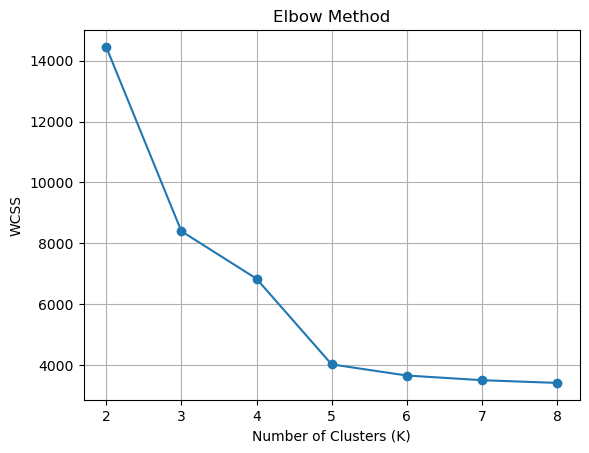

In [ ]:

plt.plot(range(2, 9), WCSS, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.xticks(range(2, 9))
plt.grid()

plt.show()

Using the Elbow Method, the optimal number of clusters was identified as **K = 5**, where the WCSS reduction started to slow down significantly, indicating that adding more clusters would provide only a relatively small improvement

**Fitting Model Wlith Best K**

In [582]:
km = KMeans(n_clusters= 5, random_state=42, n_init=10)
clusters = km.fit_predict(usage_behave_df_cp)

c:\new conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


In [583]:
usage_behave_df_cp['clusters'] = clusters

**Model Evaluation**

In [614]:
score = silhouette_score(usage_behave_df_cp, clusters)

print('Silhouette Score:', score)

Silhouette Score: 0.5805389324173613


### **Cluster Profiling**

In [585]:
usage_behave_df = usage_behave_df.drop(columns='customer_id')

In [587]:
usage_behave_df['clusters'] = clusters

In [588]:
usage_behave_df.head()

,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week,clusters
0,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1,0
1,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7,1
2,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1,0
3,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2,0
4,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9,0


In [591]:
usage_behave_df['clusters'].value_counts().reset_index().sort_values(by='clusters')

,clusters,count
1,0,525
2,1,454
0,2,565
3,3,418
4,4,38


In [597]:
cluster_profile = usage_behave_df.groupby('clusters').mean().reset_index()

cluster_profile

,clusters,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
0,0,2831.451238,37.858857,14.101714,9.865436,8.013143,2.938286,1.967238,1.030476,3.222857,3.011429,38.007619,2.952190
1,1,326.191189,12.281938,1.072467,2.264182,0.589207,2.898238,1.503965,0.453744,1.317181,4.995595,7.896476,0.454405
2,2,1097.710265,22.185310,2.954513,13.866848,1.311150,6.035752,2.465841,1.127434,2.366372,4.001770,29.853097,1.998938
3,3,621.982057,9.430861,1.374641,3.079003,0.634450,14.076316,4.500478,9.129187,21.722488,2.021531,14.019139,5.004306
4,4,7488.589474,82.052632,2.723684,7.534413,1.513158,24.076316,2.515789,2.289474,5.605263,4.184211,19.026316,2.189474


Silhouette Score: 0.5805389324173613


### HCA Model

In [ ]:
import scipy.cluster.hierarchy as sch


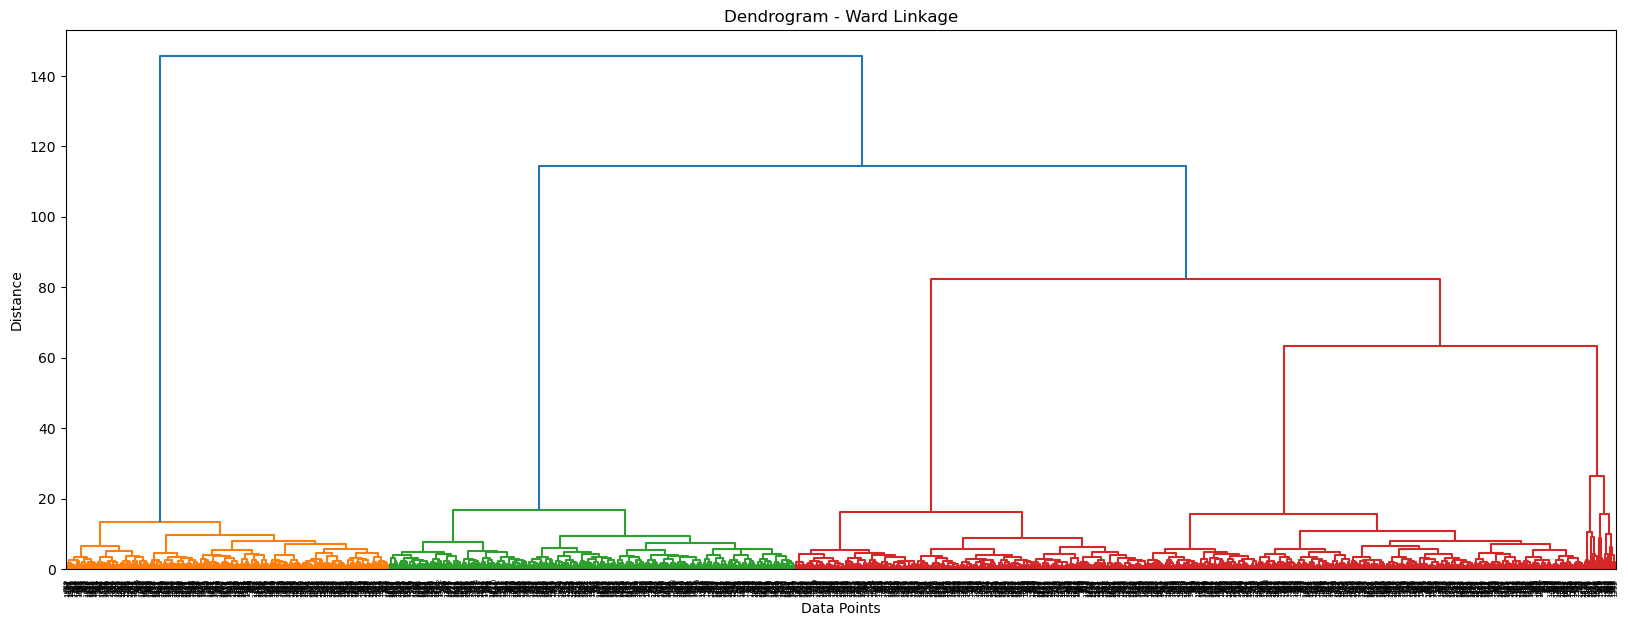

In [618]:
plt.figure(figsize=(20, 7))
dendogram = sch.dendrogram(sch.linkage(usage_behave_df_cp , method='ward')  )

plt.title("Dendrogram - Ward Linkage")
plt.xlabel("Data Points")
plt.ylabel("Distance")



plt.show()

In [619]:
hac_ward = AgglomerativeClustering(n_clusters=5 , linkage='ward')
hac_ward_label = hac_ward.fit_predict(usage_behave_df_cp)


In [634]:
pd.Series(hac_ward_label).value_counts().sort_index()

0     40
1    454
2    523
3    418
4    565
Name: count, dtype: int64

In [633]:
hac_average = AgglomerativeClustering(
    n_clusters=5,
    linkage='average'
)

hac_average_label = hac_average.fit_predict(usage_behave_df_cp)

In [635]:
pd.Series(hac_average_label).value_counts().sort_index()


0      17
1    1542
2       7
3     418
4      16
Name: count, dtype: int64

In [636]:
from sklearn.metrics import adjusted_rand_score

ari_ward = adjusted_rand_score(
    clusters,
    hac_ward_label
)

ari_average = adjusted_rand_score(
    clusters,
    hac_average_label
)

print("Ward ARI:", ari_ward)
print("Average ARI:", ari_average)

Ward ARI: 0.9984771918288056
Average ARI: 0.3066962328563184


In [645]:
print("HAC Ward:", silhouette_score(usage_behave_df_cp, hac_ward_label))
print("HAC Average:", silhouette_score(usage_behave_df_cp, hac_average_label))

HAC Ward: 0.5803457774342846
HAC Average: 0.47987830938667425


In [641]:
results = pd.DataFrame({
    'Method': ['KMeans', 'HAC Ward', 'HAC Average'],
    'Clusters': [
        len(set(clusters)),
        len(set(hac_ward_label)),
        len(set(hac_average_label)),
        
    ],
    'ARI vs KMeans': [
        1.0,
        adjusted_rand_score(clusters, hac_ward_label),
        adjusted_rand_score(clusters, hac_average_label),
    
    ]
})

results

,Method,Clusters,ARI vs KMeans
0,KMeans,5,1.000000
1,HAC Ward,5,0.998477
2,HAC Average,5,0.306696


### HAC vs KMeans Comparison

The results show that HAC with Ward linkage achieved an ARI of 0.9985, indicating an almost identical clustering structure compared to KMeans.

However, HAC with Average linkage achieved a lower ARI of 0.3067, indicating considerably less agreement with KMeans.

This suggests that the choice of linkage method significantly affects the clustering results. Ward linkage produced groups very similar to KMeans, while Average linkage generated a different grouping structure.

Overall, KMeans and HAC with Ward linkage identified almost the same customer segments.

### DBSCAN Model

**choose eps**

In [669]:
neighbors = NearestNeighbors(n_neighbors=24)
neighbors.fit(usage_behave_df_cp)
distance , indices = neighbors.kneighbors(usage_behave_df_cp)

k_distance = np.sort(distance[:,-1])

In [670]:
distance.shape

(2000, 24)

In [671]:
k_distance

array([0.7394191 , 0.74886087, 0.75149009, ..., 8.19039814, 8.20501018,
       8.5159227 ], shape=(2000,))

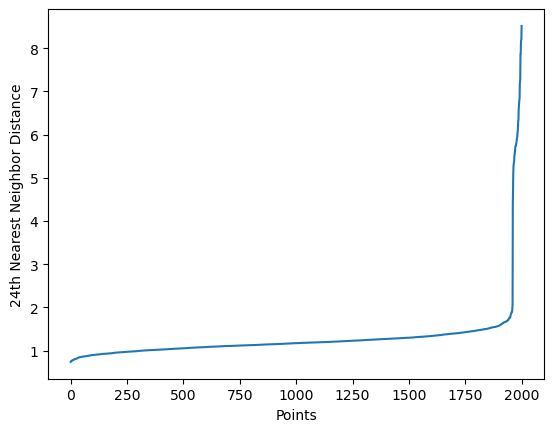

In [674]:
plt.plot(k_distance )
plt.xlabel("Points")
plt.ylabel("24th Nearest Neighbor Distance")
plt.show()

In [677]:
dbscan = DBSCAN(eps=1.75 , min_samples=24)

In [678]:
dbscan_labels = dbscan.fit_predict(usage_behave_df_cp)

In [688]:
pd.Series(dbscan_labels).value_counts().sort_index(ascending=False).drop(-1).count()

np.int64(4)

In [680]:
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0) # we using set here because set will be drop the redundatnt values

n_noise = np.sum(dbscan_labels == -1)

noise_percentage = (n_noise / len(dbscan_labels)) * 100

print('Number of Clusters:', n_clusters)
print('Number of Noise Points:', n_noise)
print('Noise Percentage:', round(noise_percentage, 2), '%')

Number of Clusters: 4
Number of Noise Points: 40
Noise Percentage: 2.0 %


In [689]:
usage_behave_df['DBSCAN_clusters'] = dbscan_labels

In [692]:
noise_customers = usage_behave_df[usage_behave_df['DBSCAN_clusters'] == -1]

noise_customers.head(10)

,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week,clusters,DBSCAN_clusters
16,7159.4,72.6,0.0,1.6,0.0,1.9,1.8,0,4,7,6,1.1,4,-1
87,6022.6,72.0,5.7,2.0,0.0,3.0,1.9,0,0,5,5,0.0,4,-1
117,7958.2,74.1,0.0,3.7,1.4,37.4,4.6,9,27,2,17,5.5,4,-1
120,7548.0,74.6,0.6,2.8,0.0,14.8,4.2,9,24,3,9,5.3,4,-1
201,8736.0,86.3,6.1,14.2,0.8,9.5,3.1,2,2,4,39,3.6,4,-1
324,7162.8,91.8,0.0,1.4,1.6,35.7,2.1,0,0,4,10,1.3,4,-1
348,7062.2,82.5,2.6,13.6,3.3,44.1,3.8,0,6,4,30,1.4,4,-1
528,6673.9,83.6,1.8,12.2,0.4,36.4,2.1,0,0,5,30,3.0,4,-1
612,7293.9,76.9,0.1,2.2,1.3,0.4,0.9,1,2,5,8,0.7,4,-1
670,7533.9,86.8,0.0,3.0,1.0,14.2,4.6,9,16,3,17,4.5,4,-1


In [693]:
print('Noise Customers:', len(noise_customers))

Noise Customers: 40


In [701]:
noise_profile = usage_behave_df.groupby(
    usage_behave_df['DBSCAN_clusters'] == -1
).mean(numeric_only=True).drop(columns=['clusters' , 'DBSCAN_clusters'])

noise_profile.index = ['Normal Customers', 'Noise Customers']

noise_profile

,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
Normal Customers,1274.932245,21.308265,5.156531,7.810809,2.787347,6.199541,2.544286,2.65102,6.480612,3.544898,23.564796,2.535663
Noise Customers,7512.417500,82.062500,3.272500,7.655192,1.867500,22.907500,2.470000,2.27500,5.450000,4.150000,20.050000,2.267500


### PCA

In [702]:
from sklearn.decomposition import PCA


pca = PCA()

pca.fit(usage_behave_df_cp)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

In [703]:
print(explained_variance)
print(cumulative_variance)

[0.46059658 0.26733511 0.09889208 0.07153367 0.02843414 0.0143436
 0.01295731 0.01012925 0.00971983 0.00830013 0.00726763 0.00669829
 0.00379239]
[0.46059658 0.72793168 0.82682376 0.89835743 0.92679157 0.94113518
 0.95409249 0.96422174 0.97394157 0.98224169 0.98950932 0.99620761
 1.        ]


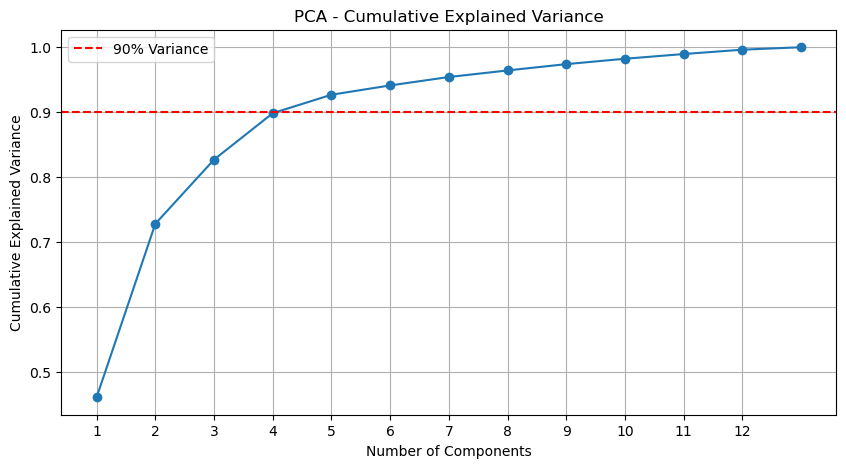

In [706]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.90,
    color='red',
    linestyle='--',
    label='90% Variance'
)

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')

plt.xticks(range(1, 13))
plt.grid()
plt.legend()

plt.show()